In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
sectors = {
    "RELIANCE.NS": "Energy", "ONGC.NS": "Energy", "BPCL.NS": "Energy",
    "COALINDIA.NS": "Energy", "NTPC.NS": "Energy", "POWERGRID.NS": "Energy",
    "TCS.NS": "IT", "INFY.NS": "IT", "WIPRO.NS": "IT", "HCLTECH.NS": "IT", "TECHM.NS": "IT",
    "HDFCBANK.NS": "Banks", "ICICIBANK.NS": "Banks", "SBIN.NS": "Banks",
    "KOTAKBANK.NS": "Banks", "AXISBANK.NS": "Banks", "INDUSINDBK.NS": "Banks",
    "BAJFINANCE.NS": "Finance", "BAJAJFINSV.NS": "Finance",
    "SBILIFE.NS": "Finance", "HDFCLIFE.NS": "Finance",
    "HINDUNILVR.NS": "Consumer", "ITC.NS": "Consumer", "NESTLEIND.NS": "Consumer",
    "BRITANNIA.NS": "Consumer", "TATACONSUM.NS": "Consumer", "TITAN.NS": "Consumer",
    "ASIANPAINT.NS": "Consumer",
    "MARUTI.NS": "Auto", "M&M.NS": "Auto", "EICHERMOT.NS": "Auto", "HEROMOTOCO.NS": "Auto",
    "SUNPHARMA.NS": "Pharma", "CIPLA.NS": "Pharma", "DRREDDY.NS": "Pharma",
    "DIVISLAB.NS": "Pharma", "APOLLOHOSP.NS": "Pharma",
    "ULTRACEMCO.NS": "Materials", "GRASIM.NS": "Materials", "TATASTEEL.NS": "Materials",
    "JSWSTEEL.NS": "Materials", "HINDALCO.NS": "Materials",
    "LT.NS": "Other", "ADANIPORTS.NS": "Other", "BHARTIARTL.NS": "Other",
}
tickers = list(sectors.keys())
print(len(tickers))

45


In [3]:
data = yf.download(tickers, start="2015-01-01", end="2026-09-30", auto_adjust=True)
close = data["Close"]
close.to_csv("close.csv")

[*********************100%***********************]  45 of 45 completed


In [4]:
close = pd.read_csv("close.csv", index_col=0, parse_dates=True)
print(close.shape)
print(close.isna().sum().sort_values(ascending=False).head(5))

(2900, 45)
HDFCLIFE.NS      710
SBILIFE.NS       678
ASIANPAINT.NS      0
APOLLOHOSP.NS      0
ADANIPORTS.NS      0
dtype: int64


In [5]:
returns = close.pct_change()
print(returns.tail())

            ADANIPORTS.NS  APOLLOHOSP.NS  ASIANPAINT.NS  AXISBANK.NS  \
Date                                                                   
2026-09-23       0.006852       0.026427       0.002655     0.000402   
2026-09-24      -0.012173      -0.019903      -0.025377    -0.045608   
2026-09-25       0.001512       0.000056       0.021440     0.030257   
2026-09-28      -0.024776      -0.003262      -0.009820    -0.010226   
2026-09-29       0.044905      -0.022686      -0.002066     0.001818   

            BAJAJFINSV.NS  BAJFINANCE.NS  BHARTIARTL.NS   BPCL.NS  \
Date                                                                
2026-09-23       0.012669       0.034100       0.008805  0.006856   
2026-09-24      -0.045600      -0.058666      -0.020401 -0.027395   
2026-09-25       0.004937       0.015173      -0.005791  0.004559   
2026-09-28      -0.010728      -0.011937      -0.007841 -0.020259   
2026-09-29      -0.005479      -0.011371      -0.000113 -0.009595   

           

In [6]:
momentum = close.shift(21) / close.shift(252) - 1
reversal = -(close / close.shift(5) - 1)

In [7]:
mom_rank = momentum.rank(axis=1, pct=True) - 0.5
rev_rank = reversal.rank(axis=1, pct=True) - 0.5

In [8]:
def sector_neutralize(signal):
    neutral = signal.copy()
    for sector in set(sectors.values()):
        cols = []
        for t in signal.columns:
            if sectors[t] == sector:
                cols.append(t)
        sector_mean = signal[cols].mean(axis=1)
        neutral[cols] = signal[cols].sub(sector_mean, axis=0)
    return neutral

mom_neutral = sector_neutralize(mom_rank)
rev_neutral = sector_neutralize(rev_rank)

In [9]:
def backtest(signal, rebalance_days, cost_bps):
    weights = signal.sub(signal.mean(axis=1), axis=0)
    weights = weights.div(weights.abs().sum(axis=1), axis=0)
    weights = weights.fillna(0)
    weights = weights.iloc[::rebalance_days].reindex(weights.index).ffill()
    weights = weights.shift(1).fillna(0)
    gross_pnl = (weights * returns).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    cost = turnover * cost_bps / 10000
    net_pnl = gross_pnl - cost
    return net_pnl["2016":], turnover["2016":]

In [10]:
def metrics(pnl, turnover):
    ann_return = pnl.mean() * 252
    ann_vol = pnl.std() * np.sqrt(252)
    sharpe = ann_return / ann_vol
    cum = pnl.cumsum()
    max_dd = (cum - cum.cummax()).min()
    avg_turnover = turnover.mean()
    return [round(ann_return, 4), round(ann_vol, 4), round(sharpe, 2),
            round(max_dd, 4), round(avg_turnover, 4)]

In [11]:
next_returns = returns.shift(-1)

mom_ic = mom_neutral.corrwith(next_returns, axis=1, method="spearman")
rev_ic = rev_neutral.corrwith(next_returns, axis=1, method="spearman")

print("Momentum IC:", mom_ic.mean(), " IC IR:", mom_ic.mean() / mom_ic.std())
print("Reversal IC:", rev_ic.mean(), " IC IR:", rev_ic.mean() / rev_ic.std())

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


Momentum IC: 0.0032215432447432616  IC IR: 0.019395257056762743
Reversal IC: 0.03674055480519733  IC IR: 0.22436931265065543


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


In [12]:
results = {}

pnl, turn = backtest(mom_rank, 21, 10)
results["Momentum raw"] = metrics(pnl, turn)

pnl, turn = backtest(mom_neutral, 21, 10)
results["Momentum sector-neutral"] = metrics(pnl, turn)
mom_pnl = pnl

pnl, turn = backtest(rev_rank, 5, 10)
results["Reversal raw"] = metrics(pnl, turn)

pnl, turn = backtest(rev_neutral, 5, 10)
results["Reversal sector-neutral"] = metrics(pnl, turn)
rev_pnl = pnl

In [13]:
blend = 0.5 * mom_neutral + 0.5 * rev_neutral
blend_pnl, blend_turn = backtest(blend, 5, 10)
results["Blend sector-neutral"] = metrics(blend_pnl, blend_turn)

In [14]:
table = pd.DataFrame(results, index=["Ann return", "Ann vol", "Sharpe", "Max DD", "Turnover"]).T
print(table)
print("PnL correlation mom vs rev:", mom_pnl.corr(rev_pnl))

                         Ann return  Ann vol  Sharpe  Max DD  Turnover
Momentum raw                 0.0020   0.0684    0.03 -0.2391    0.0192
Momentum sector-neutral     -0.0172   0.0525   -0.33 -0.2180    0.0234
Reversal raw                -0.0143   0.0645   -0.22 -0.2857    0.2704
Reversal sector-neutral     -0.0032   0.0504   -0.06 -0.2539    0.2832
Blend sector-neutral        -0.0081   0.0506   -0.16 -0.2487    0.2159
PnL correlation mom vs rev: -0.045424210478422905


In [15]:
def sharpe(pnl):
    return pnl.mean() / pnl.std() * np.sqrt(252)

print("Train 2016-2022 Sharpe:", sharpe(blend_pnl["2016":"2022"]))
print("Test 2023-2026 Sharpe:", sharpe(blend_pnl["2023":]))

Train 2016-2022 Sharpe: 0.40468928450620306
Test 2023-2026 Sharpe: -1.590358929626281


In [16]:
for cost in [0, 5, 10, 20, 30]:
    pnl, turn = backtest(rev_neutral, 5, cost)
    print("Cost", cost, "bps -> Reversal Sharpe:", round(sharpe(pnl), 2))

Cost 0 bps -> Reversal Sharpe: 1.37
Cost 5 bps -> Reversal Sharpe: 0.65
Cost 10 bps -> Reversal Sharpe: -0.06
Cost 20 bps -> Reversal Sharpe: -1.42
Cost 30 bps -> Reversal Sharpe: -2.6


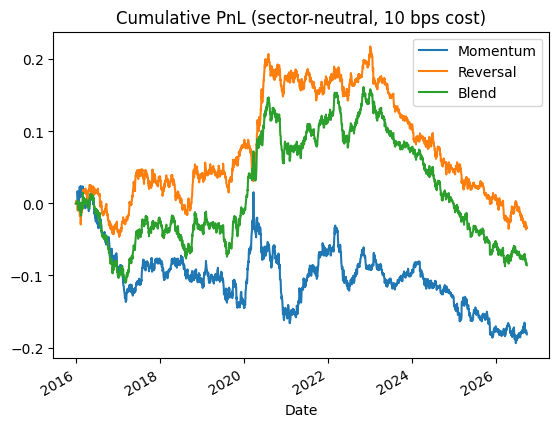

In [17]:
mom_pnl.cumsum().plot(label="Momentum")
rev_pnl.cumsum().plot(label="Reversal")
blend_pnl.cumsum().plot(label="Blend")
plt.legend()
plt.title("Cumulative PnL (sector-neutral, 10 bps cost)")
plt.savefig("pnl.png")
plt.show()

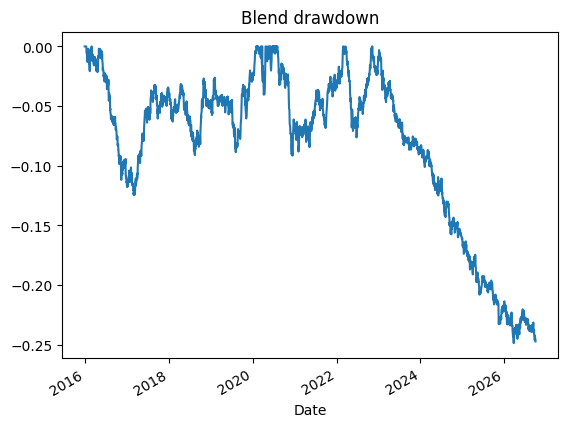

In [18]:
cum = blend_pnl.cumsum()
(cum - cum.cummax()).plot(title="Blend drawdown")
plt.savefig("drawdown.png")
plt.show()

In [19]:
pnl, turn = backtest(mom_neutral, 21, 0)
print("Momentum gross Sharpe:", round(sharpe(pnl), 2))

pnl, turn = backtest(rev_neutral, 5, 0)
print("Reversal gross Sharpe:", round(sharpe(pnl), 2))

pnl, turn = backtest(blend, 5, 0)
print("Blend gross Sharpe:", round(sharpe(pnl), 2))

Momentum gross Sharpe: -0.22
Reversal gross Sharpe: 1.37
Blend gross Sharpe: 0.92


In [20]:
for span in [5, 10, 20]:
    rev_smooth = rev_neutral.ewm(span=span).mean()
    pnl, turn = backtest(rev_smooth, 1, 10)
    print("Span", span,
          " Train Sharpe:", round(sharpe(pnl["2016":"2022"]), 2),
          " Turnover:", round(turn.mean(), 3))

Span 5  Train Sharpe: 0.54  Turnover: 0.376
Span 10  Train Sharpe: 0.73  Turnover: 0.289
Span 20  Train Sharpe: 0.89  Turnover: 0.216


In [21]:
best_span = 20      # best TRAIN Sharpe in span test (0.89)
rev_smooth = rev_neutral.ewm(span=best_span).mean()
pnl, turn = backtest(rev_smooth, 1, 10)
smooth_pnl = pnl

print("Train 2016-2022 Sharpe:", round(sharpe(pnl["2016":"2022"]), 2))
print("Test 2023-2026 Sharpe:", round(sharpe(pnl["2023":]), 2))
print("Turnover:", round(turn.mean(), 3), " vs old:", 0.2832)

Train 2016-2022 Sharpe: 0.89
Test 2023-2026 Sharpe: -0.37
Turnover: 0.216  vs old: 0.2832


In [22]:
for cost in [0, 5, 10, 20]:
    old_pnl, old_turn = backtest(rev_neutral, 5, cost)
    new_pnl, new_turn = backtest(rev_smooth, 1, cost)
    print("Cost", cost, "bps -> Old Sharpe:", round(sharpe(old_pnl), 2),
          " Smoothed Sharpe:", round(sharpe(new_pnl), 2))

Cost 0 bps -> Old Sharpe: 1.37  Smoothed Sharpe: 1.57
Cost 5 bps -> Old Sharpe: 0.65  Smoothed Sharpe: 1.05
Cost 10 bps -> Old Sharpe: -0.06  Smoothed Sharpe: 0.53
Cost 20 bps -> Old Sharpe: -1.42  Smoothed Sharpe: -0.51


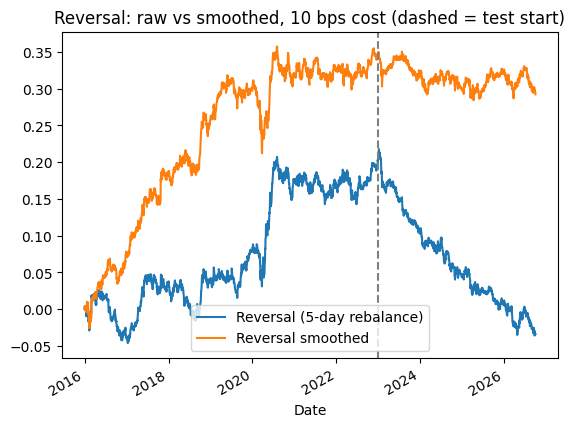

In [23]:
rev_pnl.cumsum().plot(label="Reversal (5-day rebalance)")
smooth_pnl.cumsum().plot(label="Reversal smoothed")
plt.axvline(pd.Timestamp("2023-01-01"), color="grey", linestyle="--")
plt.legend()
plt.title("Reversal: raw vs smoothed, 10 bps cost (dashed = test start)")
plt.savefig("smooth_vs_raw.png")
plt.show()

In [24]:
gross_smooth, t = backtest(rev_smooth, 1, 0)
print("Train gross Sharpe:", round(sharpe(gross_smooth["2016":"2022"]), 2))
print("Test gross Sharpe:", round(sharpe(gross_smooth["2023":]), 2))

Train gross Sharpe: 1.85
Test gross Sharpe: 0.89


In [25]:
yearly = smooth_pnl.groupby(smooth_pnl.index.year).apply(sharpe)
print(yearly.round(2))

Date
2016    1.46
2017    2.02
2018    1.32
2019    0.83
2020    0.25
2021    0.14
2022    0.52
2023   -0.80
2024   -0.42
2025    0.65
2026   -1.09
dtype: float64


In [26]:
smooth_ic = rev_smooth.corrwith(next_returns, axis=1, method="spearman")
yearly_ic = smooth_ic.groupby(smooth_ic.index.year).mean()
print(yearly_ic.round(4))

Date
2015    0.0449
2016    0.0330
2017    0.0369
2018    0.0125
2019    0.0220
2020    0.0072
2021    0.0259
2022    0.0173
2023    0.0238
2024    0.0121
2025    0.0202
2026    0.0027
dtype: float64


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
